


Patients with liver disease have been continuously increasing because of excessive consumption of alcohol, inhale of harmful gases, intake of contaminated food, pickles and drugs. In an effort to reduce the burden on doctors, the government has hired you as a data scientist to build a predictive machine learning that would give an indication of whether a person would have a liver problem or not.

Now, as a data scientist, your goal is to build a logistic machine learning model that predicts whether a patient is healthy (non-liver patient) or ill (liver patient) based on some clinical and demographic features (or input variables) listed in the 'Data Description' section.

Proje

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Importing Data

In [ ]:
liver_data = pd.read_csv('https://raw.githubusercontent.com/dphi-official/Datasets/master/liver_patient_data/indian_liver_patient_dataset.csv')
liver_data.head(10)

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Liver_Problem
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
5,46,Male,1.8,0.7,208,19,14,7.6,4.4,1.30,1
6,26,Female,0.9,0.2,154,16,12,7.0,3.5,1.00,1
7,29,Female,0.9,0.3,202,14,11,6.7,3.6,1.10,1
8,17,Male,0.9,0.3,202,22,19,7.4,4.1,1.20,2
9,55,Male,0.7,0.2,290,53,58,6.8,3.4,1.00,1


Data Exploration

In [ ]:
liver_data.shape

(500, 11)

From the data we have 500 observations and 11 features

In [ ]:
liver_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         500 non-null    int64  
 1   Gender                      500 non-null    object 
 2   Total_Bilirubin             500 non-null    float64
 3   Direct_Bilirubin            500 non-null    float64
 4   Alkaline_Phosphotase        500 non-null    int64  
 5   Alamine_Aminotransferase    500 non-null    int64  
 6   Aspartate_Aminotransferase  500 non-null    int64  
 7   Total_Protiens              500 non-null    float64
 8   Albumin                     500 non-null    float64
 9   Albumin_and_Globulin_Ratio  496 non-null    float64
 10  Liver_Problem               500 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 43.1+ KB


Handling Missing Values

In [ ]:
liver_data.isnull().sum()

,0
Age,0
Gender,0
Total_Bilirubin,0
Direct_Bilirubin,0
Alkaline_Phosphotase,0
Alamine_Aminotransferase,0
Aspartate_Aminotransferase,0
Total_Protiens,0
Albumin,0
Albumin_and_Globulin_Ratio,4


The feature Albumin_and_Globulin_Ratio has 4 missing values

In [ ]:
# let's check which observations have missing values
liver_data[liver_data.isnull().any(axis=1)]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Liver_Problem
209,45,Female,0.9,0.3,189,23,33,6.6,3.9,NaN,1
241,51,Male,0.8,0.2,230,24,46,6.5,3.1,NaN,1
253,35,Female,0.6,0.2,180,12,15,5.2,2.7,NaN,2
312,27,Male,1.3,0.6,106,25,54,8.5,4.8,NaN,2


Data Imputation

In [ ]:
# Replacing missing values with the mean value
liver_data['Albumin_and_Globulin_Ratio'] = liver_data['Albumin_and_Globulin_Ratio'].fillna(liver_data['Albumin_and_Globulin_Ratio'].mean())
liver_data.isnull().sum()

,0
Age,0
Gender,0
Total_Bilirubin,0
Direct_Bilirubin,0
Alkaline_Phosphotase,0
Alamine_Aminotransferase,0
Aspartate_Aminotransferase,0
Total_Protiens,0
Albumin,0
Albumin_and_Globulin_Ratio,0


There are now no missing values in our dataset

Data Analysis

In [ ]:
liver_data.describe()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Liver_Problem
count,500.0000,500.000000,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000
mean,44.5860,2.603800,1.117200,296.372000,82.736000,108.820000,6.44480,3.168800,0.960907,1.300000
std,16.5334,5.120238,2.066709,257.461676,194.366775,307.093557,1.08902,0.799741,0.293107,0.458717
min,4.0000,0.400000,0.100000,63.000000,10.000000,10.000000,2.70000,0.900000,0.300000,1.000000
25%,32.7500,0.800000,0.200000,175.000000,23.000000,24.750000,5.70000,2.600000,0.800000,1.000000
50%,45.0000,0.900000,0.300000,205.500000,33.500000,40.000000,6.50000,3.100000,1.000000,1.000000
75%,58.0000,2.200000,1.000000,298.000000,59.250000,79.250000,7.20000,3.800000,1.100000,2.000000
max,85.0000,75.000000,14.200000,2110.000000,2000.000000,4929.000000,9.60000,5.500000,1.900000,2.000000


In [ ]:
# Understanding which gender records most patients with liver disease
pd.crosstab(liver_data['Gender'],liver_data['Liver_Problem']).reset_index()

Liver_Problem,Gender,1,2
0,Female,85,43
1,Male,265,107


Males recorded 265 cases of Liver problems compared to their counterparts Females who recorded 85 cases.

In [ ]:
# let's check which propotion of people had liver problems
liver_data['Liver_Problem'].value_counts()

,count
Liver_Problem,
1,350
2,150


We had 350 people with Liver problems as compared to 150 people who did not have

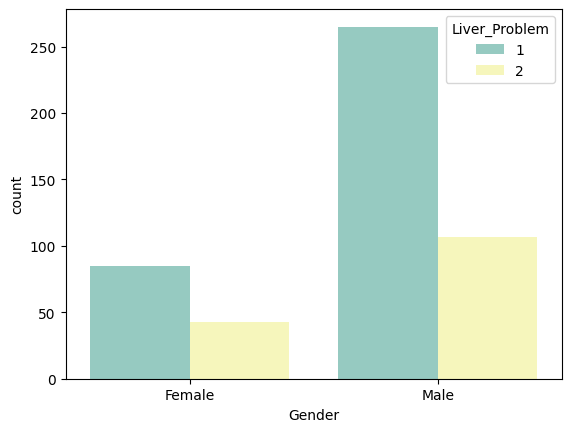

In [ ]:
# We can also visualize the propotion of gender with liver problems

sns.countplot(x='Gender',hue='Liver_Problem',data=liver_data,palette = 'Set3')
plt.show()

In [ ]:
# let's encode our Gender variable
genders = {
    'Male': 0,
    'Female': 1
}
liver_data['Gender'] = liver_data['Gender'].map(genders)
liver_data.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Liver_Problem
0,65,1,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,0,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,0,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,0,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,0,3.9,2.0,195,27,59,7.3,2.4,0.40,1


<Axes: ylabel='Age'>

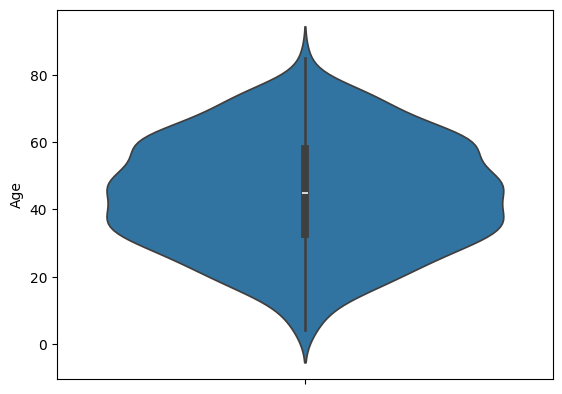

In [ ]:
sns.violinplot(y = liver_data['Age'])

Most of the participant had age between age 20 to 60

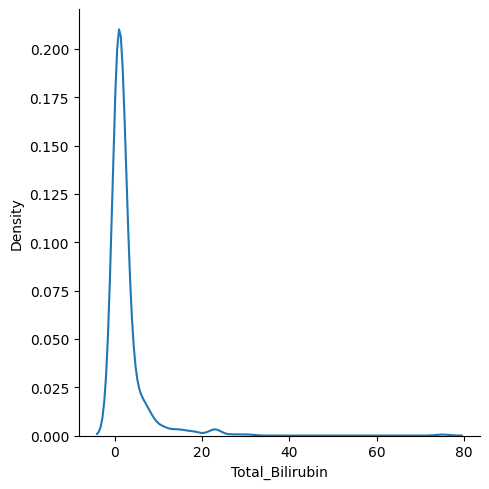

In [ ]:
sns.displot(x = liver_data['Total_Bilirubin'],kind = 'kde')

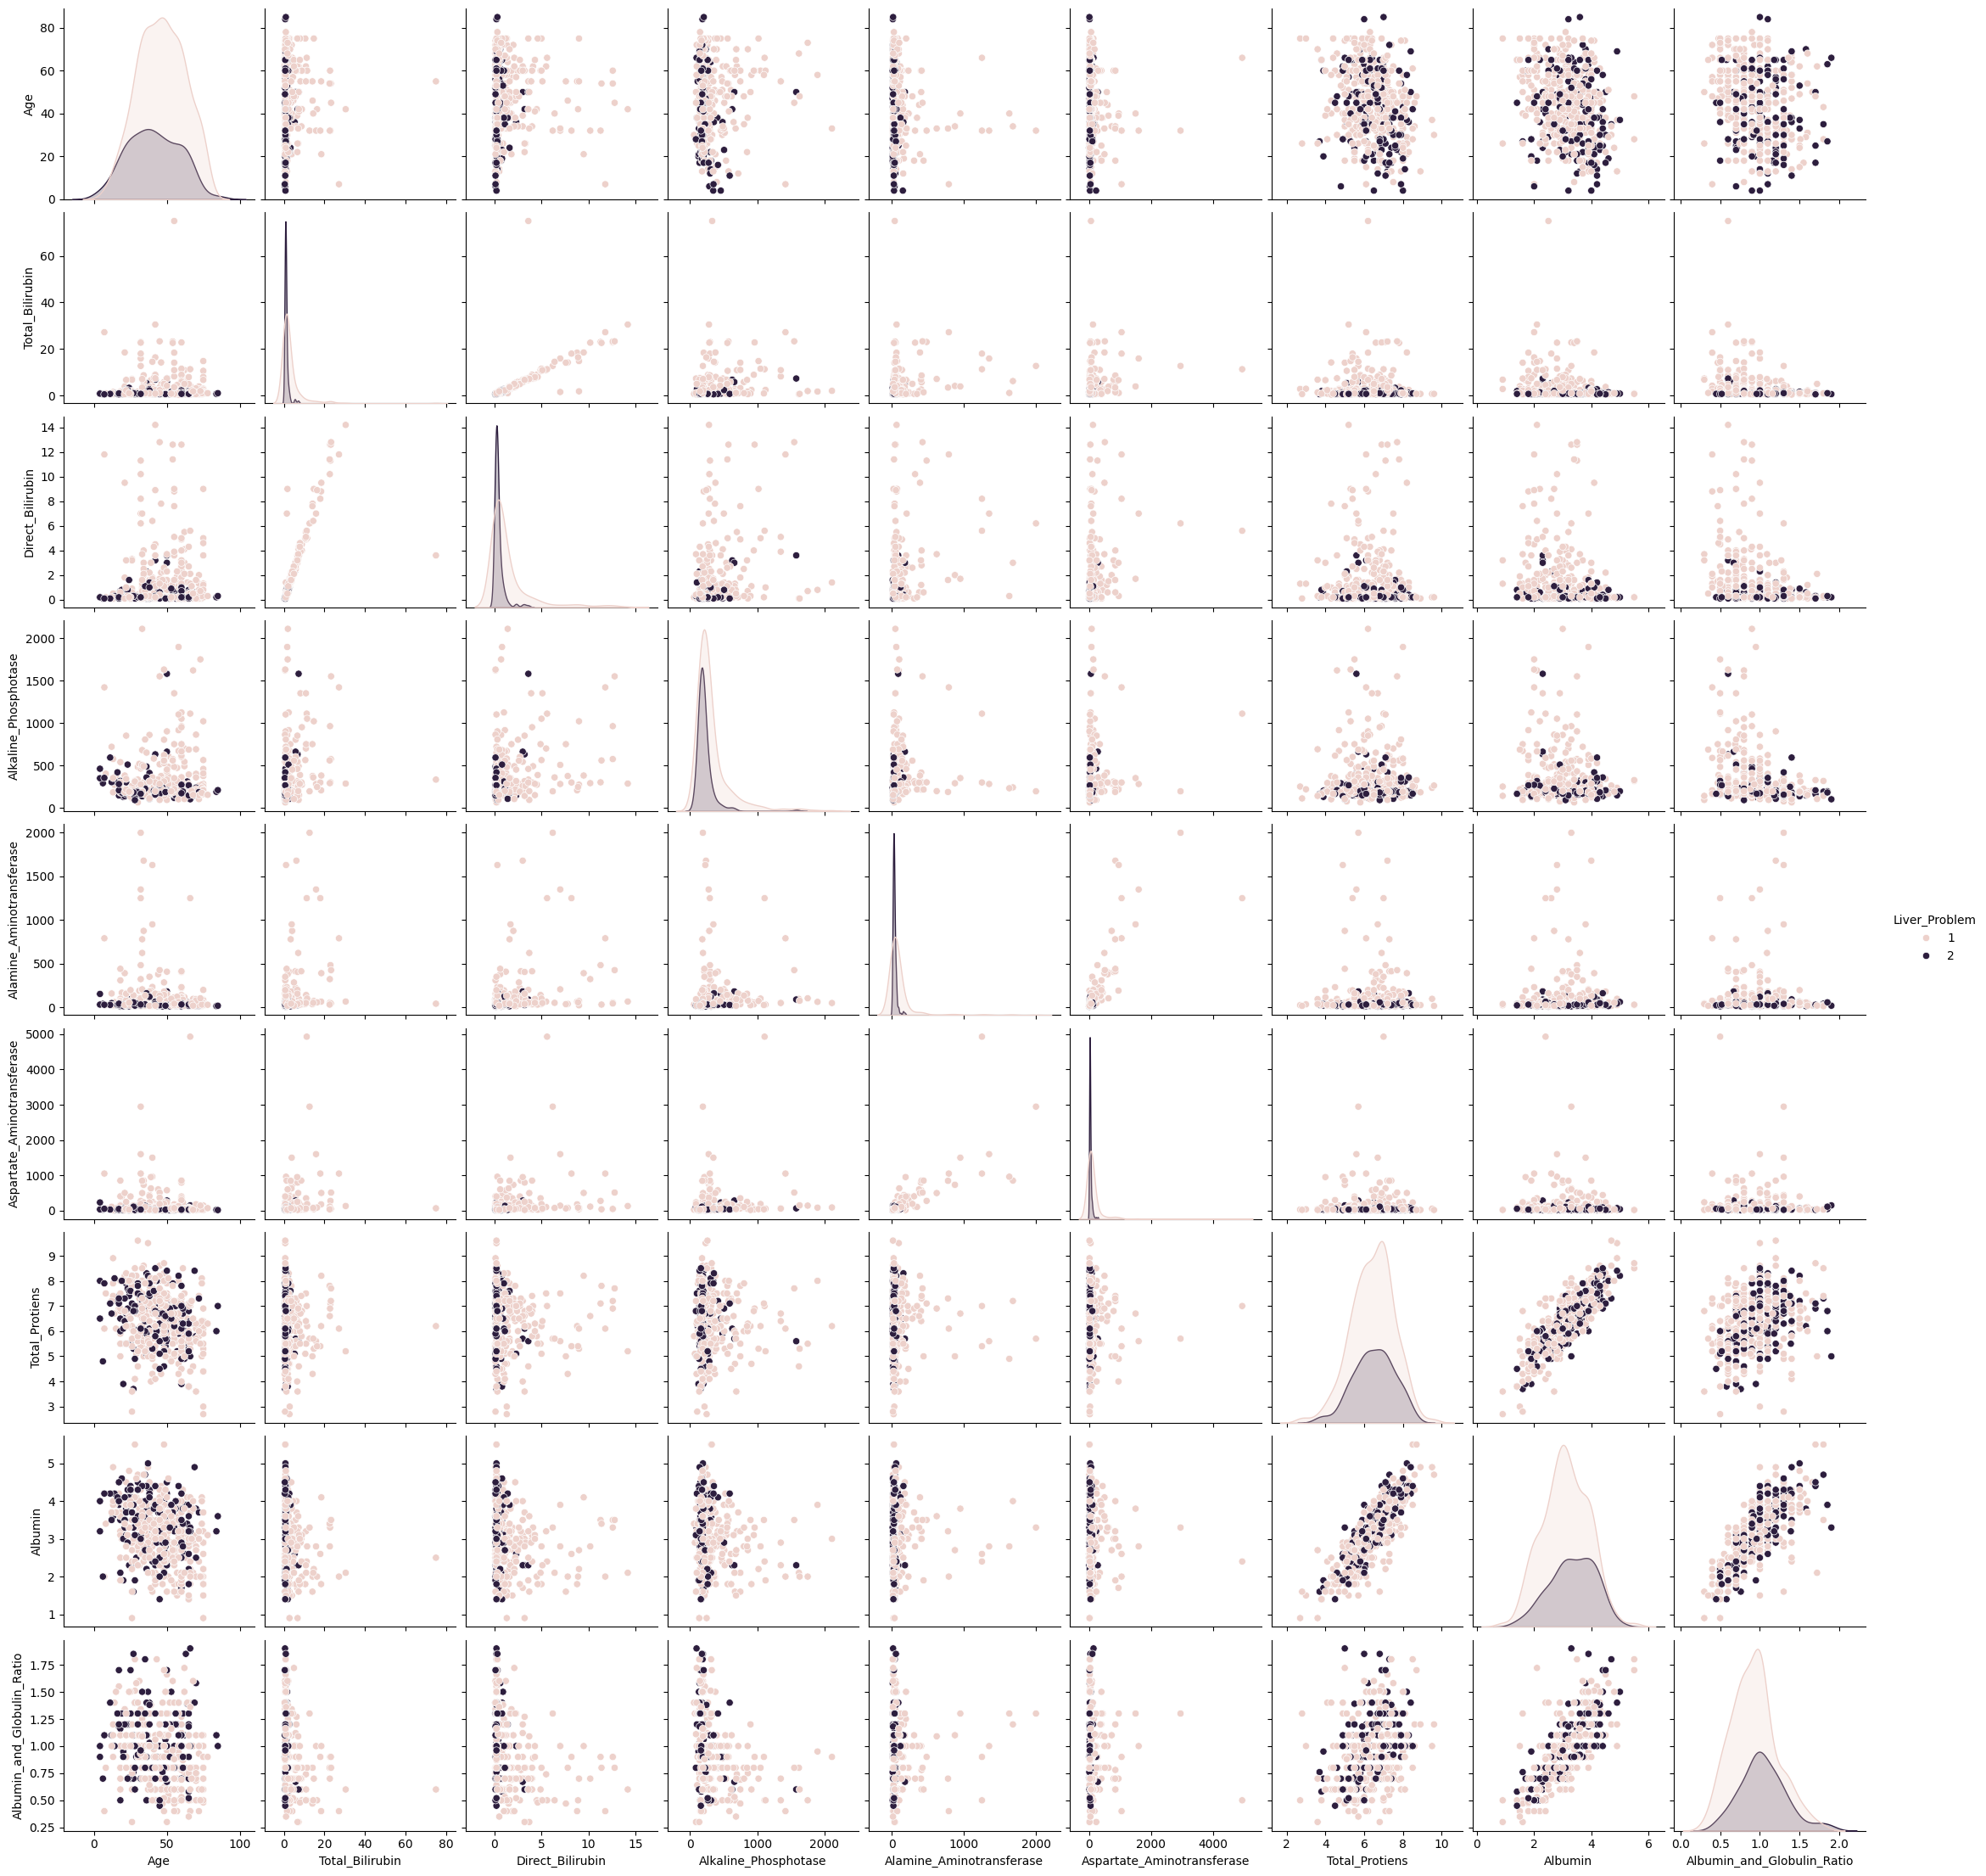

In [ ]:
sns.pairplot(liver_data,hue = 'Liver_Problem')
plt.show()

Plotting a heatmap for our data

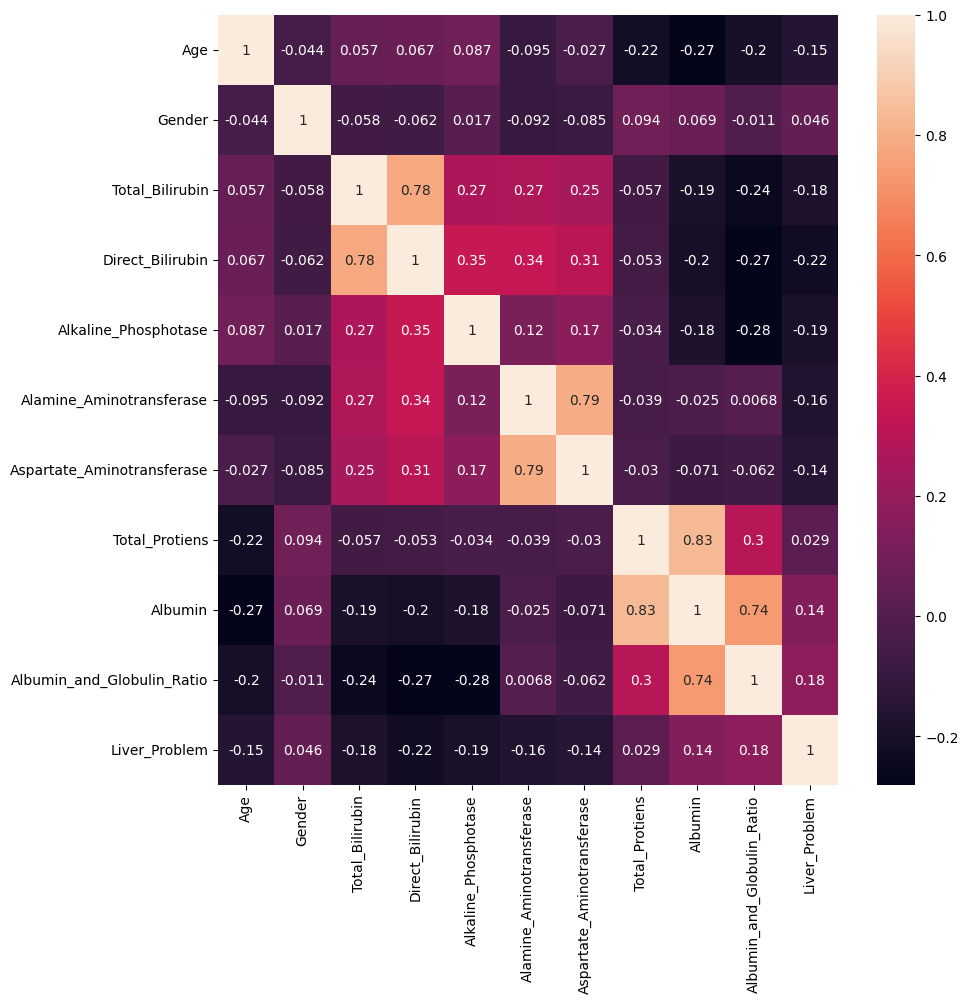

In [ ]:
plt.figure(figsize = (10,10))
sns.heatmap(liver_data.corr(),annot = True)
plt.show()

Data Splitting

In [ ]:
X = liver_data.drop('Liver_Problem',axis = 1)
y = liver_data['Liver_Problem']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 10)
(100, 10)
(400,)
(100,)


Defining our Machine Learning Algorithmn

1. Logistic Regression

In [ ]:
LogisticRegression?

In [ ]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = log_reg.predict(X_test)

Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,matthews_corrcoef
print("The accuracy score for our model is : ",accuracy_score(y_test,y_pred))
print("The confusion matrix for our model is \n : ",confusion_matrix(y_test,y_pred))
print("The Matthews correlation coefficient for our model is : ",matthews_corrcoef(y_test,y_pred))

The accuracy score for our model is :  0.65
The confusion matrix for our model is 
 :  [[58  8]
 [27  7]]
The Matthews correlation coefficient for our model is :  0.1123277558230884


Our model accounted for a 65% model accuracy

2. Decision Trees Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(X_train,y_train)


DecisionTreeClassifier()

In [ ]:
y_pred = dt.predict(X_test)
from sklearn.metrics import accuracy_score,confusion_matrix,matthews_corrcoef
print("The accuracy score for our model is : ",accuracy_score(y_test,y_pred))
print("The confusion matrix for our model is \n : ",confusion_matrix(y_test,y_pred))
print("The Matthews correlation coefficient for our model is : ",matthews_corrcoef(y_test,y_pred))

The accuracy score for our model is :  0.61
The confusion matrix for our model is 
 :  [[47 19]
 [20 14]]
The Matthews correlation coefficient for our model is :  0.12480701557801274


Our Decision Tree Classifier accounted for a 69% accuracy score which is better
than that of the Logistic Regression

3. Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

In [ ]:
y_pred = rf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix,matthews_corrcoef
print("The accuracy score for our model is : ",accuracy_score(y_test,y_pred))
print("The confusion matrix for our model is \n : ",confusion_matrix(y_test,y_pred))
print("The Matthews correlation coefficient for our model is : ",matthews_corrcoef(y_test,y_pred))

The accuracy score for our model is :  0.65
The confusion matrix for our model is 
 :  [[59  7]
 [28  6]]
The Matthews correlation coefficient for our model is :  0.09917777438300185


Our model accounted for a 65% accuracy score which is better than all the other models

MODEL HYPERPARAMETER TURNING FOR RANDOM FOREST CLASSIFIER

In [ ]:
param_grid = {
    'n_estimators':(10,500),
    'max_depth': (10,100),
    'min_samples_split':(2,10),
    'min_samples_leaf': (2,10)
}
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(rf,param_grid,cv=5)
grid_search.fit(X_train,y_train)


GridSearchCV(cv=5,
             estimator=RandomForestClassifier(max_depth=2, min_samples_leaf=10,
                                              n_estimators=2),
             param_grid={'max_depth': (10, 100), 'min_samples_leaf': (2, 10),
                         'min_samples_split': (2, 10),
                         'n_estimators': (10, 500)})

In [ ]:
grid_search.best_estimator_

RandomForestClassifier(max_depth=10, min_samples_leaf=2, min_samples_split=10,
                       n_estimators=10)

In [ ]:
rf = RandomForestClassifier(max_depth= 10,
 min_samples_leaf = 10,
 min_samples_split = 2,
 n_estimators =  10)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=10, n_estimators=10)

In [ ]:
from sklearn.metrics import accuracy_score,confusion_matrix
y_pred = rf.predict(X_test)
print("The accuracy score for our model is : ",accuracy_score(y_test,y_pred))

The accuracy score for our model is :  0.71


Our model improved to 71% which is a better model than the other models

In summary the Turned Random Forest Algortithmn is the best model to predict Liver Problems for any patients.

**Cross Validation**

KFold Validation

In [ ]:
from sklearn.model_selection import cross_validate
score = cross_validate(rf,X,y,cv = 10,scoring = ['accuracy','recall','precision'])
score

{'fit_time': array([0.01841187, 0.01662683, 0.01749635, 0.01609731, 0.01589394,
        0.01635122, 0.01595163, 0.01631021, 0.01604342, 0.01542234]),
 'score_time': array([0.0064559 , 0.00617647, 0.00636005, 0.00557232, 0.00583816,
        0.00597692, 0.00610113, 0.0055902 , 0.00570822, 0.00648832]),
 'test_accuracy': array([0.8 , 0.64, 0.74, 0.68, 0.72, 0.62, 0.68, 0.6 , 0.68, 0.62]),
 'test_recall': array([1.        , 0.82857143, 0.94285714, 0.88571429, 0.94285714,
        0.82857143, 0.77142857, 0.71428571, 0.91428571, 0.82857143]),
 'test_precision': array([0.77777778, 0.70731707, 0.75      , 0.72093023, 0.73333333,
        0.69047619, 0.77142857, 0.71428571, 0.71111111, 0.69047619])}

Evaluation for our KFold Evaluation

In [ ]:
print("The mean test accuracy is :",score['test_accuracy'].mean())
print("The mean test recall is :",score['test_recall'].mean())
print("The mean test precision is :",score['test_precision'].mean())

The mean test accuracy is : 0.678
The mean test recall is : 0.8657142857142859
The mean test precision is : 0.726713619461776
